<small>📌 <b>먼저 내 노트로 저장하기</b></small><br><small>이 노트는 내 구글 드라이브의 『Colab Notebooks』 폴더(자동 사본으로 만들었으면 『배화 Colab 실습』 폴더)에 저장돼요.</small><br><small>사이트의 「▶ 내 Colab 노트 만들기」로 열었으면 사본·공유가 이미 돼 있어요 — 아래 ①~③ 은 건너뛰어도 돼요.</small><br><br><small>① 맨 위 <b>파일 → Drive에 사본 저장</b> (안 하면 쓴 게 사라져요)</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_copy.jpg" width="300"><br><br><small>② 사본이 열리면 오른쪽 위 <b>공유</b> 단추를 눌러요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_share.jpg" width="300"><br><br><small>③ 일반 액세스에서 <b>「링크가 있는 모든 사용자」</b>를 고른 다음 <b>링크 복사</b> → 수행평가 화면 「📓 내 Colab 실습 노트」 칸에 붙여넣고 보관해요.</small><br><img src="https://baehwa-ai-2026.web.app/aisocial/img/colab_step_anyone.jpg" width="300">

# 🧠 반딧불이가 함께 깜박이는 조건(쿠라모토 동기화) — 딥러닝(신경망) 빈칸 실습

서울대 수리과학부에서 다루는 주제예요. 반딧불이가 함께 깜박이는 조건(쿠라모토 동기화)을(를) 논문 공식(동기화 정도 r = √(1 − Kc/K))으로 흉내 낸 연습용 데이터예요. 결합 세기 K · 진동수 퍼짐을(를) 바꿔 가며 동기화 정도이(가) 어떻게 달라지는지 찾아봐요.

**예측할 것:** 결과(동기화 정도 중간보다 높음) (0 또는 1) — 동기화 정도이(가) 중간값보다 높으면 1, 아니면 0이에요

> ⚠️ 연습용 합성 데이터(실제 측정 아님)

수업 「#20 당도 아삭함 과일 채소 딥러닝」·「MNIST 딥러닝」에서 배운 순서 그대로예요: 불러오기 → 결측치 → 이상치(IQR) → 속성 살펴보기 → 정규화 → 신경망 설계(Sequential·Dense) → compile → fit → evaluate → predict → confusion matrix → ROC·AUC.

`______` 빈칸에 알맞은 **함수 이름이나 낱말**을 넣고 ▶ 실행해요. 막히면 **오픈북** — 클래스룸 실습 파일을 펴 보고 같은 코드를 찾아 써요(단계마다 📖).

In [ ]:
# 0. 준비 — 그대로 실행해요 (한글 그래프 글꼴 · 매번 같은 결과가 나오게 시드 고정)
!pip -q install koreanize-matplotlib
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from keras.utils import set_random_seed
set_random_seed(42)      # 모델이 매번 똑같이 학습되게(아니면 실행할 때마다 정확도가 조금씩 달라져요)

## 1. 데이터 불러오기
📖 **오픈북** — 「#20 과일 채소 딥러닝」 숙제00 `pd.read_csv(url)`

In [ ]:
dc = pd.______("https://baehwa-ai-2026.web.app/dataproject/csv/c2335_c.csv")      # 힌트: CSV 를 읽는 함수
print(dc.shape)
dc.______()      # 힌트: 앞 5줄만 보기

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)


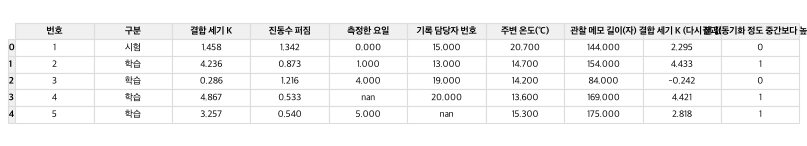

## 1-1. 결측치(빈칸) 처리
머신러닝 노트 2번과 같아요 — 이번에 쓰는 열에 빈칸이 있는 줄을 지워요.

📖 **오픈북** — 「#16 펭귄-분류」 숙제05 `df.isnull().sum()` · 숙제06 `df.dropna(axis=0)` · 「#12 결측치(seoultemp)」

In [ ]:
use_cols = ["결합 세기 K", "진동수 퍼짐", "결과(동기화 정도 중간보다 높음)"]
print(dc[use_cols].______().sum())   # 힌트: 빈칸인지 True/False — 열마다 개수
dc = dc.______(subset=use_cols)       # 힌트: 빈칸 있는 줄 지우기
print('빈칸 지운 뒤', dc.shape)      # 빈칸 있던 줄이 통째로 빠져서 행 수가 줄어요

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

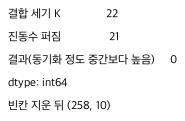

## 1-2. 이상치(IQR) 처리
머신러닝 노트 3번과 같은 IQR 이에요. 값 종류가 적은 열(0/1 등)은 건너뛰어요.

📖 **오픈북** — 「#14 Iris 데이터 전처리(이상치)」 숙제14 `quantile(0.25)` · 숙제15 `Q3 + 1.5 * IQR`

In [ ]:
for col in ["결합 세기 K", "진동수 퍼짐"]:
    q1 = dc[col].______(0.25)        # 힌트: 분위수
    q3 = dc[col].quantile(0.75)
    iqr = q3 - q1
    if iqr == 0 or dc[col].nunique() <= 5: continue      # 값 종류가 적은 열은 건너뛰기
    하한 = q1 - 1.5 * iqr
    상한 = q3 + ______ * iqr          # 힌트: 숫자예요(함수 아님) — IQR 의 몇 배인지
    dc = dc[(dc[col] >= 하한) & (dc[col] <= 상한)]
print('이상치 지운 뒤', dc.shape)

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 1-3. 속성 살펴보기 — pairplot · 상관 heatmap
신경망에 넣기 전에 속성끼리 어떤 관계인지 눈으로 봐요(그대로 실행). 색은 정답(0·1)이에요 — 두 색 점이 잘 갈라지는 속성일수록 신경망이 배우기 쉬워요. 📖 **오픈북** — 「#16 펭귄-분류」 `sns.pairplot` · 「#14 Iris 데이터 전처리」 `sns.heatmap`

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.pairplot(dc[["결합 세기 K", "진동수 퍼짐", "결과(동기화 정도 중간보다 높음)"]].sample(min(len(dc), 300), random_state=0), hue="결과(동기화 정도 중간보다 높음)", corner=True, plot_kws={'s': 12})
plt.show()
plt.figure(figsize=(7, 5))
sns.heatmap(dc[["결합 세기 K", "진동수 퍼짐", "결과(동기화 정도 중간보다 높음)"]].corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

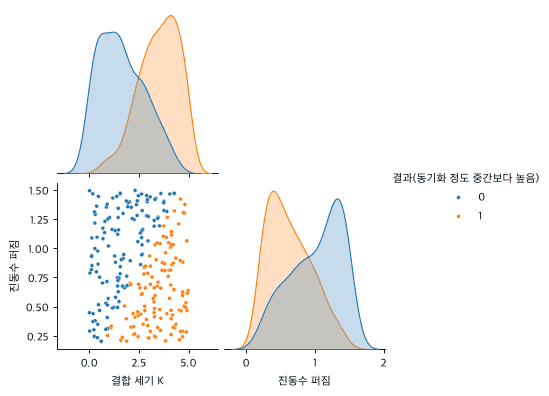
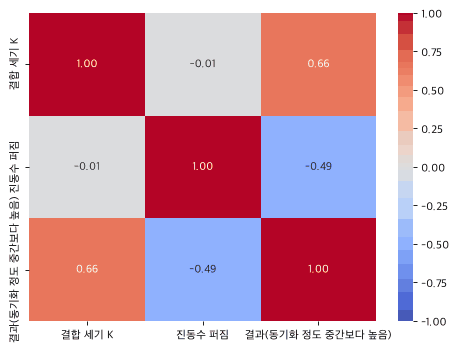

## 2. 특징(X)·정답(y) 고르고 0~1 로 맞추기(정규화)
신경망은 숫자 크기가 비슷해야 잘 배워요(예: 몸무게 50 과 키 160 을 둘 다 0~1 로). MNIST 에서 픽셀을 255 로 나눠 0~1 로 만든 것과 같은 일이에요. 먼저 학습용·시험용으로 나누고, **학습용의 최솟값·최댓값**으로 둘 다 맞춰요(시험지를 미리 보지 않기).

📖 **오픈북** — 「MNIST 딥러닝」 숙제03 정규화 · 「#20 과일 채소 딥러닝」 숙제01 `X = df[[...]]`, `y = df[...]`

In [ ]:
X = dc[["결합 세기 K", "진동수 퍼짐"]]
y = dc["결과(동기화 정도 중간보다 높음)"]
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = ______(X, y, test_size=0.3, random_state=42)      # 힌트: 나누는 함수
mn, mx = X_train.min(), X_train.max()      # 정규화 기준은 학습용에서만 (시험지를 미리 보지 않기)
rng = (mx - mn).replace(0, 1)      # 값이 한 가지뿐인 열은 0 으로 나누지 않게
X_train, X_test = (X_train - mn) / rng, (X_test - mn) / rng      # 0~1 로 맞추기 — ⚠️ 이 셀을 두 번 실행하면 또 줄어요(다시 하려면 1번부터)
print(len(X_train), len(X_test))

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 3. 신경망 설계하기
입력층(2) → 은닉층(16) → 은닉층(8) → 출력층(2: 0 이냐 1 이냐).

- **Input층** = 맨 처음, 속성이 몇 개 들어오는지 알려주는 자리(계산은 안 해요).
- **층(Dense)** = 계산하는 칸(노드)이 한 줄로 모인 것. **은닉층**은 입력과 출력 사이에서 생각하는 칸들이에요.
- **16·8** = 칸 수. 정해진 답은 없어요 — 수업 과일 채소 실습(32·16)보다 데이터가 작아서 조금 줄였어요. 바꿔 보고 정확도가 어떻게 되는지 봐도 좋아요.
- **relu** = 음수는 0 으로 바꾸는 규칙(은닉층에 써요). **softmax** = 마지막 칸들을 「0일 확률·1일 확률」처럼 더해서 1 이 되게 바꾸는 규칙이에요.
- **왜 출력을 Dense(2)로?** 「0 이다/1 이다」둘 중 하나를 고르는 문제라 칸을 2개 두고 softmax 로 각각의 확률을 내요(둘을 더하면 1). Dense(1)+sigmoid 로도 같은 걸 할 수 있지만, 여기선 수업에서 배운 softmax 방식을 그대로 써요.

📖 **오픈북** — 「#20 과일 채소 딥러닝」 숙제01 `Sequential()` · `Dense(32, activation='relu')` · `Dense(3, activation='softmax')`

In [ ]:
from keras.models import Sequential
from keras.layers import Dense, Input
model = ______()      # 힌트: 층을 차례로 쌓는 모델
model.add(Input(shape=(2,)))      # 입력 칸 개수(속성 2개)를 먼저 알려줘요
model.add(______(16, activation='relu'))      # 힌트: 층 이름
model.add(Dense(8, activation='relu'))
model.add(Dense(2, activation='______'))      # 힌트: 확률로 나오게 하는 활성화 함수

## 4. 학습 방법 정하기 (compile)
📖 **오픈북** — 「#20 과일 채소 딥러닝」 숙제02 · 「MNIST 딥러닝」 숙제07

In [ ]:
model.______(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])      # 힌트: 학습 방법 정하기(손실·최적화·평가 지표)

## 5. 학습하기 (fit) → 평가하기 (evaluate)
📖 **오픈북** — 「#20 과일 채소 딥러닝」 숙제03·04 · 「MNIST 딥러닝」 숙제07·08

(위에서 시드를 고정해 둬서 늘 비슷하게 나와요 — 그래도 기기·버전에 따라 **숫자가 아주 조금 달라도 괜찮아요**. 비슷한 범위면 맞는 거예요.)

In [ ]:
model.______(X_train, y_train, epochs=100, verbose=0)      # 힌트: 학습시키기 (verbose=0 은 진행 줄을 숨겨요)
print('시험 [손실, 정확도]', model.______(X_test, y_test, verbose=0))      # 힌트: 성능 평가
base = max(y_test.mean(), 1 - y_test.mean())
print('기준선 — 아무 계산 없이 더 많은 쪽으로만 찍어도', round(base, 2))

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)

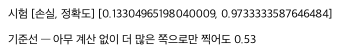

## 6. 예측해 보기 (predict)
📖 **오픈북** — 「MNIST 딥러닝」 숙제09 `model.predict` · `np.argmax`

In [ ]:
import numpy as np
p = model.______(X_test[:5], verbose=0)      # 힌트: 예측하기
print('예측', np.argmax(p, axis=1), '정답', list(y_test[:5]))

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)



## 6-1. 시험용 전체로 혼동행렬(confusion matrix) 보기
**혼동행렬**은 예측이 실제와 맞았는지·어떻게 틀렸는지를 표로 보여줘요. 대각선 칸이 맞춘 개수예요.

📖 **오픈북** — 「#16 펭귄-분류」 KNN 숙제 `accuracy_score` · `confusion_matrix` · `ConfusionMatrixDisplay`

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
p_all = model.predict(X_test, verbose=0)
pred_all = np.argmax(p_all, axis=1)
print('정확도', ______(y_test, pred_all))      # 힌트: 정확도 재는 함수
cm = ______(y_test, pred_all)                  # 힌트: 혼동행렬 만들기
ConfusionMatrixDisplay(cm).plot()
plt.show()

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)


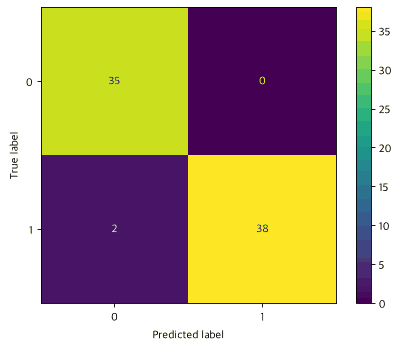

## 6-2. ROC 곡선 · AUC
곡선이 왼쪽 위 모서리에 붙을수록 잘 가려내는 거예요. **AUC**(곡선 아래 넓이)는 1에 가까울수록 좋고, **0.5면 동전 던져 찍는 것과 같아요.**

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
proba_all = p_all[:, 1]      # 「1」일 확률(소프트맥스 두 번째 칸)
fpr, tpr, _ = ______(y_test, proba_all)      # 힌트: ROC 곡선 좌표
auc = ______(y_test, proba_all)              # 힌트: 곡선 아래 넓이
plt.plot(fpr, tpr, label=f'신경망 (AUC={auc:.2f})'); plt.plot([0, 1], [0, 1], '--', color='gray', label='찍기 (AUC=0.50)')
plt.xlabel('거짓 양성 비율(FPR)'); plt.ylabel('진짜 양성 비율(TPR)'); plt.legend(); plt.show()
print('AUC', round(auc, 3))

▶ 이렇게 나오면 맞아요 (숫자는 조금 달라도 괜찮아요)


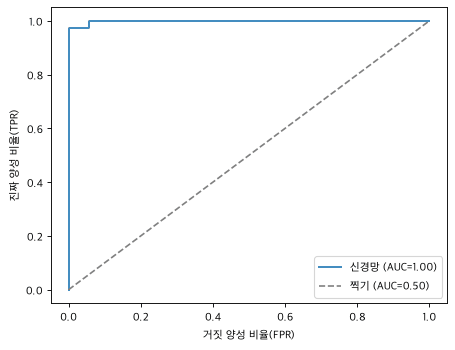

## 7. 결과 읽기
보고서 「한계」 칸에 적어요.
- 정확도가 **기준선**(더 많은 쪽으로만 찍은 정확도)보다 높았나요? 기준선과 비슷하면 신경망이 거의 배운 게 없다는 뜻이에요.
- 머신러닝 노트의 점수(R²)와는 **재는 방법이 달라서** 숫자를 그대로 비교하면 안 돼요. R² 는 숫자를 얼마나 가깝게 맞혔는지, 정확도는 0·1 을 몇 개 맞혔는지예요.
- 데이터가 몇백 줄뿐이면 신경망이 꼭 좋지는 않아요 — 그것도 **발견**이에요.